## Preparación para Google Colab

1. Sube este notebook a Google Colab y ejecuta la siguiente celda de instalación.
2. Ejecuta la configuración y selecciona `ventas_12_semanas.csv`, ubicado en `Datasets/`, cuando se solicite.
3. Ejecuta las demás celdas en orden.

**Para ejecutar la práctica solo es obligatorio subir el recorte `ventas_12_semanas.csv`.** Si también deseas reproducir la extracción desde el dataset completo, selecciona además `train.csv` y `stores.csv` en esa misma ventana. El notebook comprobará que el recorte coincide con las filas originales.

En esta computadora, los ocho CSV están en `Datasets/`. El repositorio Git incluye únicamente `ventas_12_semanas.csv`; los siete CSV originales permanecen locales y están ignorados. Selecciona un kernel de Python y ejecuta la celda de instalación si necesitas las librerías. Los gráficos y resultados se muestran dentro del notebook, sin generar archivos auxiliares.

In [ ]:
%pip install -q numpy pandas matplotlib scikit-learn tensorflow keras

In [1]:
from pathlib import Path

candidatos = [Path('Datasets'), Path('LSTM_LAFAVORITA/Datasets'), Path('.')]
DATA_DIR = next((p for p in candidatos if (p / 'ventas_12_semanas.csv').exists()), Path('Datasets'))
if not (DATA_DIR / 'ventas_12_semanas.csv').exists():
    try:
        from google.colab import files
        print('Sube ventas_12_semanas.csv')
        uploaded = files.upload()
        if 'ventas_12_semanas.csv' not in uploaded:
            raise FileNotFoundError('Debes subir ventas_12_semanas.csv.')
        DATA_DIR = Path('.')
    except ImportError as exc:
        raise FileNotFoundError('Coloca ventas_12_semanas.csv en Datasets/.') from exc
print(f'Datos reales: {(DATA_DIR / "ventas_12_semanas.csv").resolve()}')

Datos reales: Datasets/ventas_12_semanas.csv


<div style="color:#3c4d5a; border-top: 7px solid #42A5F5; border-bottom: 7px solid #42A5F5; padding: 5px; text-align: center; text-transform: uppercase"><h1>Redes Neuronales Recurrentes (RNN) y Series Temporales</h1> </div>

**Estimación de stock para Corporación Favorita, Ecuador.**

Se predice la demanda del día actual (**t**) a partir de las ventas y otras variables de los **6 días anteriores** (**t-6 ... t-1**).

La variable de salida **Y es `stock`**. Para esta práctica, `stock` toma los valores reales de `sales` y representa la cantidad de demanda que se desea cubrir. El origen no contiene existencias de inventario: estimamos cobertura de demanda, según la definición acordada para el ejercicio.

El proceso incluye la preparación de ventanas, la normalización, el entrenamiento de una LSTM y el cálculo de RMSE. Las variables de entrada, el tamaño de la ventana, el horizonte y la categoría se pueden elegir.

Esta práctica está estructurada de la siguiente manera:

- [Preparación de datos](#Preparacion)
- [Desarrollo de RNN](#RNN)
- [Conclusiones](#Conclusiones)
- [Referencias](#Referencias)

<div id="Preparacion" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Preparación de datos</h2> </div>

**Paso 1. Conocer los archivos originales de Corporación Favorita**

En esta computadora, `Datasets/` conserva los siete CSV del dataset original y el recorte utilizado en esta práctica. Git versiona únicamente el recorte `ventas_12_semanas.csv`; los originales pueden descargarse desde el enlace de Referencias:

| Archivo | Contenido | Uso en esta práctica |
|---|---|---|
| `train.csv` | Histórico de ventas por fecha, tienda y familia | Fuente de las 12 semanas seleccionadas |
| `stores.csv` | Ciudad, provincia, tipo y grupo de cada tienda | Verificar que la tienda 44 está en Quito, Pichincha |
| `oil.csv` | Precio diario del petróleo | Disponible, sin incorporarlo a las entradas del modelo |
| `holidays_events.csv` | Feriados y eventos, con ámbito y traslados | Disponible, sin incorporarlo al modelo |
| `transactions.csv` | Número de transacciones por tienda y fecha | Disponible, sin incorporarlo al modelo |
| `test.csv` | Fechas futuras de la competencia, sin la venta real | No se usa como prueba de esta práctica |
| `sample_submission.csv` | Plantilla para enviar predicciones a Kaggle | No contiene ventas observadas para evaluar la red |
| `ventas_12_semanas.csv` | Recorte real de `train.csv`, sin inventar registros | Datos utilizados para los gráficos y la LSTM |

Guardar todos los archivos permite revisar su procedencia. El modelo actual utiliza las ventas y promociones del recorte, junto con el día de la semana. No se han añadido petróleo, feriados o transacciones a sus variables de entrada.

**Paso 2. Seleccionar la tienda y las 12 semanas**

Se eligió la **tienda 44**, situada en **Quito, Pichincha** según `stores.csv`, y el periodo del **22 de mayo al 13 de agosto de 2017**, inclusive. Son 12 semanas completas de lunes a domingo.

El filtro aplicado a `train.csv` es:

```python
(store_nbr == 44) & ('2017-05-22' <= date) & (date <= '2017-08-13')
```

Cada fila representa la venta de una familia en una tienda durante un día. El recorte contiene **84 días × 33 familias = 2.772 registros**. Al elegir una familia, quedan 84 observaciones diarias.

Si `train.csv` está disponible, la siguiente celda lo lee por bloques de 100.000 filas y aplica ese filtro. Después compara el resultado con el CSV incluido. La lectura por bloques evita cargar todo el histórico en memoria. Si solo se subió el recorte a Colab, la celda lo carga directamente y comprueba su huella de integridad.

**Paso 3. Revisar las columnas y validar los datos**

| Columna | Descripción |
|---|---|
| `id` | Identificador del registro |
| `date` | Fecha de la venta |
| `store_nbr` | Identificador de la tienda |
| `family` | Familia, como `BEVERAGES`, `DAIRY` o `PRODUCE` |
| `sales` | Cantidad vendida de esa familia en ese día |
| `onpromotion` | Número de artículos de esa familia que estaban en promoción |

Se comprueban las columnas, los faltantes, los duplicados, los valores no negativos y la cobertura de los 84 días. No se rellenan faltantes ni se generan ventas artificiales.

`sales` puede incluir fracciones por productos vendidos por peso. No representa dólares, clientes o tickets. `onpromotion` no es un porcentaje de descuento. Los enlaces de procedencia están en [Referencias](#Referencias).

In [2]:
import pandas as pd
import numpy as np
from hashlib import sha256

ETIQUETAS = {'BEVERAGES': 'Bebidas', 'DAIRY': 'Lácteos', 'PRODUCE': 'Frutas y verduras',
             'BREAD/BAKERY': 'Panadería', 'MEATS': 'Carnes', 'CLEANING': 'Limpieza'}
CATEGORIAS = list(ETIQUETAS)

# Reproduce el filtro del histórico completo, si también está disponible.
recorte_original = None
if (DATA_DIR / 'train.csv').exists():
    partes = []
    registros_originales = 0
    for bloque in pd.read_csv(DATA_DIR / 'train.csv', chunksize=100_000):
        registros_originales += len(bloque)
        mascara = bloque['store_nbr'].eq(44) & bloque['date'].between('2017-05-22', '2017-08-13')
        if mascara.any():
            partes.append(bloque.loc[mascara])
    if not partes:
        raise ValueError('El histórico no contiene ventas para la tienda y el periodo seleccionados.')
    recorte_original = pd.concat(partes, ignore_index=True)
    recorte_original['date'] = pd.to_datetime(recorte_original['date'])
    recorte_original = recorte_original.sort_values(['date', 'family']).reset_index(drop=True)
    print(f'Histórico: {registros_originales:,} filas. Recorte: {len(recorte_original):,} filas.')
else:
    print('Se utiliza el recorte incluido, sin cargar el histórico completo.')

if (DATA_DIR / 'stores.csv').exists():
    tiendas = pd.read_csv(DATA_DIR / 'stores.csv')
    tienda = tiendas.loc[tiendas['store_nbr'].eq(44)]
    if len(tienda) != 1 or tienda.iloc[0]['city'] != 'Quito' or tienda.iloc[0]['state'] != 'Pichincha':
        raise ValueError('Los metadatos no coinciden con la tienda documentada.')
    print(tienda.to_string(index=False))

assert sha256((DATA_DIR / 'ventas_12_semanas.csv').read_bytes()).hexdigest() == '5f1734770419cf26102a481175bc1312689bb52740ba329d86b61a12231721b4', 'El archivo no coincide con los datos documentados.'
ventas = pd.read_csv(DATA_DIR / 'ventas_12_semanas.csv', parse_dates=['date'])
columnas = ['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']
if ventas.columns.tolist() != columnas:
    raise ValueError(f'Columnas esperadas: {columnas}')
if ventas.isna().any().any() or ventas.duplicated(['date', 'store_nbr', 'family']).any():
    raise ValueError('El archivo contiene faltantes o registros duplicados.')
if not np.isfinite(ventas[['sales', 'onpromotion']].to_numpy()).all():
    raise ValueError('Las ventas y promociones deben ser números finitos.')
if not ventas[['sales', 'onpromotion']].ge(0).all().all():
    raise ValueError('Las ventas y promociones deben ser no negativas.')
ventas = ventas.sort_values(['date', 'family']).reset_index(drop=True)
if (len(ventas) != 2772 or ventas['family'].nunique() != 33
        or not ventas['store_nbr'].eq(44).all()
        or not pd.DatetimeIndex(ventas['date'].unique()).equals(pd.date_range('2017-05-22', '2017-08-13'))):
    raise ValueError('Se esperan 84 días completos y 33 familias de la tienda 44.')

if recorte_original is not None:
    pd.testing.assert_frame_equal(ventas, recorte_original, check_exact=False, rtol=1e-12, atol=1e-9)
    print('Comprobación: el recorte incluido coincide con las ventas originales.')
ventas.head()

Histórico: 3,000,888 filas. Recorte: 2,772 filas.
 store_nbr  city     state type  cluster
        44 Quito Pichincha    A        5
Comprobación: el recorte incluido coincide con las ventas originales.
Out[0]: 
        id       date  store_nbr      family   sales  onpromotion
0  2848890 2017-05-22         44  AUTOMOTIVE    14.0            0
1  2848891 2017-05-22         44   BABY CARE     0.0            0
2  2848892 2017-05-22         44      BEAUTY    14.0            1
3  2848893 2017-05-22         44   BEVERAGES  8876.0           29
4  2848894 2017-05-22         44       BOOKS     0.0            0


In [3]:
print('Registros originales:', len(ventas))
print('Categorías:', ventas['family'].nunique())
print('Días:', ventas['date'].nunique(), '| Semanas:', ventas['date'].nunique() // 7)
print('Periodo:', ventas['date'].min().date(), 'a', ventas['date'].max().date())
print('Local: tienda 44, Quito, Pichincha. El dataset no identifica su dirección o marca comercial.')

Registros originales: 2772
Categorías: 33
Días: 84 | Semanas: 12
Periodo: 2017-05-22 a 2017-08-13
Local: tienda 44, Quito, Pichincha. El dataset no identifica su dirección o marca comercial.


#### PASO 4. ANÁLISIS EXPLORATORIO

Antes de entrenar la red se revisa cómo cambian las ventas. Se muestran seis categorías: **bebidas, lácteos, frutas y verduras, panadería, carnes y limpieza**. Las otras 27 categorías permanecen en el archivo original y se pueden seleccionar para predecir.

La celda siguiente calcula y representa:

1. **Ventas acumuladas por categoría:** suma de `sales` durante las 12 semanas. Las familias pueden tener unidades de medida diferentes, por lo que este gráfico no compara ingresos.
2. **Evolución semanal:** suma de las ventas de lunes a domingo. Cada categoría usa su propia escala vertical para que se aprecien sus variaciones.
3. **Patrón por día de la semana:** media de ventas de cada lunes, martes, etc. Se divide por el promedio diario de la misma categoría y se multiplica por 100. Un índice de **147** significa aproximadamente **47% más** que su promedio.

`PRODUCE` incluye frutas y verduras. El dataset no permite separar ambas mediante esta columna. Estos gráficos describen las ventas del supermercado, no las compras a proveedores.

Out[0]: 
                  Día de mayor venta media  ...  Cambio últimas 4 / primeras 4 semanas (%)
Bebidas                            domingo  ...                                      -10.0
Lácteos                            domingo  ...                                      -12.4
Frutas y verduras                  domingo  ...                                       -5.7
Panadería                          domingo  ...                                      -10.3
Carnes                             viernes  ...                                       -6.7
Limpieza                           domingo  ...                                        1.4

[6 rows x 3 columns]


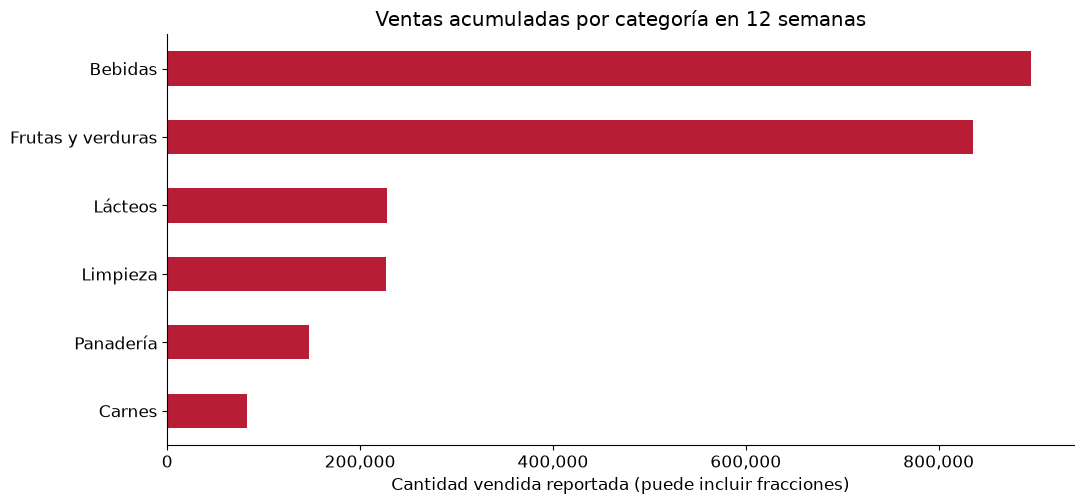

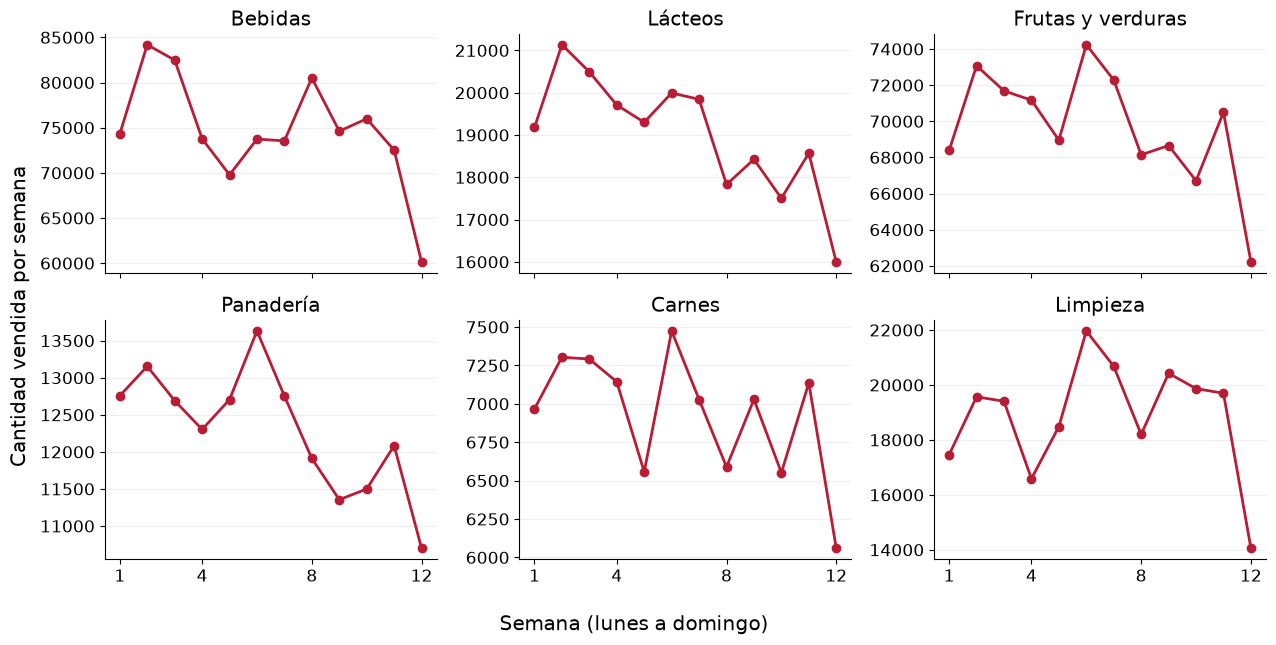

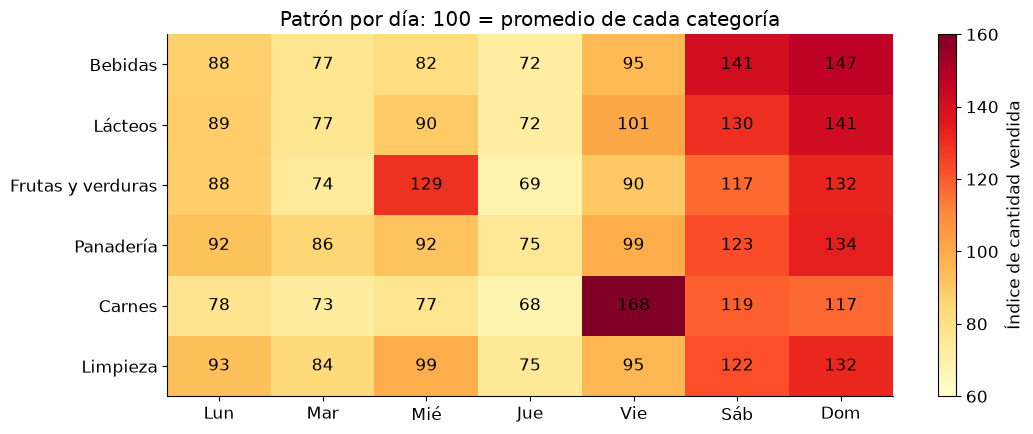

In [4]:
from matplotlib import pyplot as plt

seleccion = ventas[ventas['family'].isin(CATEGORIAS)].copy()
seleccion['semana'] = ((seleccion['date'] - ventas['date'].min()).dt.days // 7) + 1
semanal = seleccion.groupby(['semana', 'family'])['sales'].sum().unstack()[CATEGORIAS]
semanal.columns = [ETIQUETAS[c] for c in CATEGORIAS]
totales = seleccion.groupby('family')['sales'].sum().reindex(CATEGORIAS)
totales.index = [ETIQUETAS[c] for c in CATEGORIAS]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(11, 5.2))
totales.sort_values().plot.barh(ax=ax, color='#B91C35')
ax.set(xlabel='Cantidad vendida reportada (puede incluir fracciones)', ylabel='', title='Ventas acumuladas por categoría en 12 semanas')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, category in zip(axes.flat, semanal.columns):
    ax.plot(semanal.index, semanal[category], color='#B91C35', marker='o', linewidth=2)
    ax.set_title(category)
    ax.set_xticks([1, 4, 8, 12])
    ax.grid(axis='y', alpha=0.2)
fig.supxlabel('Semana (lunes a domingo)')
fig.supylabel('Cantidad vendida por semana')
fig.tight_layout()
plt.show()

seleccion['dia'] = seleccion['date'].dt.dayofweek
diario = seleccion.groupby(['family', 'dia'])['sales'].mean().unstack().reindex(CATEGORIAS)
indice = diario.div(diario.mean(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
image = ax.imshow(indice, cmap='YlOrRd', aspect='auto', vmin=60, vmax=160)
ax.set_xticks(range(7), ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'])
ax.set_yticks(range(6), [ETIQUETAS[c] for c in CATEGORIAS])
for i in range(6):
    for j in range(7):
        ax.text(j, i, f'{indice.iloc[i, j]:.0f}', ha='center', va='center', color='black')
ax.set_title('Patrón por día: 100 = promedio de cada categoría')
fig.colorbar(image, ax=ax, label='Índice de cantidad vendida')
fig.tight_layout()
plt.show()

dias = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo']
resumen_ventas = pd.DataFrame({
    'Día de mayor venta media': [dias[int(diario.loc[c].idxmax())] for c in CATEGORIAS],
    'Índice del máximo diario': [indice.loc[c].max() for c in CATEGORIAS],
    'Cambio últimas 4 / primeras 4 semanas (%)': [
        (semanal[ETIQUETAS[c]].iloc[-4:].mean() / semanal[ETIQUETAS[c]].iloc[:4].mean() - 1) * 100
        for c in CATEGORIAS],
}, index=[ETIQUETAS[c] for c in CATEGORIAS])
resumen_ventas.round(1)


#### IMPORTACIÓN DE LIBRERÍAS Y DEFINICIÓN DE FUNCIONES PROPIAS

La función **`series_to_supervised`** convierte una serie temporal en una tabla de aprendizaje supervisado: agrupa varias filas consecutivas en una sola muestra.

- `n_in`: cantidad de días anteriores que recibe el modelo.
- `n_out`: cantidad de pasos futuros que se incorporan a la tabla.
- `dropnan`: elimina filas incompletas que aparecen al desplazar la serie.

Por ejemplo, con una ventana de 6 días se combinan las filas **t-6, t-5, ..., t-1**. Así, la red utiliza únicamente observaciones anteriores al día que se desea predecir.

In [5]:
from math import sqrt
import numpy as np
from matplotlib import pyplot
from pandas import read_csv
from pandas import DataFrame
from pandas import concat
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers import Input
from keras.utils import set_random_seed
set_random_seed(42)
print('Módulos importados')
 
# convert series to supervised learning
# Se combina varias filas en una sola
#n_in: las filas de la secuencia (t-n, ... t-1)
#n_out: las filas de la secuencia (t, t+1, ... t+n)
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	n_vars = 1 if type(data) is list else data.shape[1]
	df = DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg

Módulos importados


#### PASO 5. CARGA DE DATASET Y CODIFICACIÓN

Se prepara una serie independiente para cada familia. La categoría inicial es **`BEVERAGES` (bebidas)**. El modelo recibe cuatro variables numéricas:

| Variable preparada | Significado |
|---|---|
| `stock` | Venta diaria observada (`sales`); objetivo usado para estimar demanda futura |
| `promociones` | Artículos promocionados (`onpromotion`) |
| `dia_sin` | Seno del día de la semana |
| `dia_cos` | Coseno del día de la semana |

Las ventas y promociones ya son numéricas. Para representar el ciclo semanal se utilizan seno y coseno: esto permite reflejar que el domingo y el lunes son días consecutivos.

La tabla se convierte a `float32`, el tipo numérico utilizado por la red. Cada categoría queda con **84 filas y 4 variables**.

In [6]:
DATOS_POR_CATEGORIA = {}
for categoria, grupo in ventas.groupby('family'):
    serie = grupo.set_index('date')[['sales', 'onpromotion']].rename(
        columns={'sales': 'stock', 'onpromotion': 'promociones'})
    serie['dia_sin'] = np.sin(2 * np.pi * serie.index.dayofweek / 7)
    serie['dia_cos'] = np.cos(2 * np.pi * serie.index.dayofweek / 7)
    DATOS_POR_CATEGORIA[categoria] = serie.astype('float32')
CATEGORIA = 'BEVERAGES'
data_num = DATOS_POR_CATEGORIA[CATEGORIA]
print('Categoría inicial:', CATEGORIA)
print(data_num.shape, '-> (días, variables)')
data_num.head()

Categoría inicial: BEVERAGES
(84, 4) -> (días, variables)
Out[0]: 
              stock  promociones   dia_sin   dia_cos
date                                                
2017-05-22   8876.0         29.0  0.000000  1.000000
2017-05-23   7656.0         29.0  0.781832  0.623490
2017-05-24   8900.0         33.0  0.974928 -0.222521
2017-05-25   7480.0         29.0  0.433884 -0.900969
2017-05-26  14163.0         35.0 -0.433884 -0.900969


#### PASO 6. ELEGIR LOS PARÁMETROS

`VARIABLES` indica qué columnas forman X; `TARGET` indica la salida Y. Con `N_DAYS = 6` se usan los seis días anteriores. `HORIZON = 1` corresponde al día inmediatamente siguiente a la ventana. `N_TRAIN_DAYS = 8 * 7` reserva las primeras ocho semanas para entrenar.

La categoría inicial, definida en la celda anterior, es bebidas. Las funciones de predicción permiten elegir otras familias sin cambiar la arquitectura.

In [7]:
# Variables de entrada X: se puede usar cualquier subconjunto de estas columnas.
VARIABLES = ['stock', 'promociones', 'dia_sin', 'dia_cos']
# Variable de salida Y: demanda diaria que se desea cubrir.
TARGET = 'stock'
# Ventana histórica: los 6 días anteriores (t-6 ... t-1).
N_DAYS = 6
# Horizonte: 1 = el día inmediatamente siguiente a la ventana.
HORIZON = 1
# Primeras 8 semanas para entrenamiento; las 4 restantes para prueba.
N_TRAIN_DAYS = 8 * 7

#### PASO 7. NORMALIZAR Y PREPARAR LAS MUESTRAS

`preparar_datos` utiliza un `MinMaxScaler` para X y otro para Y. Ambos se ajustan **solo con los primeros 56 días**, para que el escalado no use las ventas del periodo de prueba. El escalador de Y permitirá devolver las predicciones a su escala original.

La función llama a `series_to_supervised` para construir las ventanas. El objetivo es `stock(t)` cuando el horizonte es 1, o `stock(t+horizonte-1)` cuando se pide un plazo mayor.

In [8]:
#Normaliza, aplana con series_to_supervised y separa en entrenamiento y prueba.
#Cada fila aplanada contiene N_DAYS x len(variables) columnas, por ejemplo 6 x 4 = 24.
def preparar_datos(variables, n_days, horizon=1, n_train_days=N_TRAIN_DAYS, categoria=CATEGORIA):
    if categoria not in DATOS_POR_CATEGORIA:
        raise ValueError(f'Categoría no válida: {categoria}')
    data_num = DATOS_POR_CATEGORIA[categoria]
    variables = list(variables)
    if not variables or len(set(variables)) != len(variables):
        raise ValueError('Elige al menos una variable, sin repetir columnas.')
    desconocidas = [v for v in variables if v not in data_num.columns]
    if desconocidas:
        raise ValueError(f'Variables no válidas: {desconocidas}')
    if n_days < 1 or horizon < 1:
        raise ValueError('n_days y horizon deben ser mayores o iguales a 1.')
    if not (n_days + horizon <= n_train_days < len(data_num)):
        raise ValueError('La ventana y el horizonte deben dejar datos de entrenamiento y prueba.')
    n_vars = len(variables)
    # normalize features (el escalador se ajusta solo con el periodo de entrenamiento)
    scaler_X = MinMaxScaler(feature_range=(0, 1))
    scaler_X.fit(data_num[variables].values[:n_train_days])
    scaled_X = scaler_X.transform(data_num[variables].values)
    scaler_y = MinMaxScaler(feature_range=(0, 1))
    scaler_y.fit(data_num[[TARGET]].values[:n_train_days])
    scaled_y = scaler_y.transform(data_num[[TARGET]].values)[:, 0]
    # aplanamiento: (t-n, ... t-1) de todas las variables en una sola fila
    flat = series_to_supervised(scaled_X, n_in=n_days, n_out=0)
    flat.columns = [f'{variables[j]}(t-{i})' for i in range(n_days, 0, -1) for j in range(n_vars)]
    # columna objetivo: stock en t (o t+horizon-1)
    target_name = f'{TARGET}(t)' if horizon == 1 else f'{TARGET}(t+{horizon - 1})'
    flat[target_name] = pd.Series(scaled_y).shift(-(horizon - 1)).loc[flat.index].values
    flat = flat.dropna()
    # división temporal: el objetivo de entrenamiento debe estar dentro de las primeras 8 semanas
    target_pos = flat.index.to_numpy() + horizon - 1
    is_train = target_pos < n_train_days
    flat.index = data_num.index[flat.index]
    flat.index.name = 'fecha (t)'
    X_flat = flat.drop(columns=[target_name]).to_numpy(dtype='float32')
    y = flat[target_name].to_numpy(dtype='float32')
    # reshape para la LSTM: (muestras, 24) -> (muestras, 6, 4)
    X_3d = X_flat.reshape((X_flat.shape[0], n_days, n_vars))
    return {
        'categoria': categoria, 'variables': variables, 'n_days': n_days, 'horizon': horizon,
        'scaler_X': scaler_X, 'scaler_y': scaler_y, 'scaled_X': scaled_X,
        'flat': flat, 'X_flat': X_flat,
        'train_X': X_3d[is_train], 'train_y': y[is_train],
        'test_X': X_3d[~is_train], 'test_y': y[~is_train],
    }

datos = preparar_datos(VARIABLES, N_DAYS, HORIZON)

#### PASO 8. COMPROBAR EL APLANAMIENTO

Una ventana de **6 días × 4 variables** se convierte en una fila de **24 entradas**. Al añadir el objetivo, la tabla tiene **25 columnas**. De las 84 fechas, las primeras seis se utilizan como historia inicial y quedan **78 muestras**.

Antes de entrar en la LSTM, las 24 columnas recuperan la forma tridimensional **(muestras, 6, 4)**. Las comprobaciones de la siguiente celda verifican el número de columnas y que la primera ventana coincide con las primeras seis filas normalizadas.

In [9]:
flat = datos['flat']
n_vars = len(VARIABLES)
print('Días disponibles:', len(data_num))
print('Variables de entrada:', VARIABLES)
print(f'Ventana: {N_DAYS} días | Horizonte: {HORIZON} día(s)')
print(f'Antes de aplanar: {N_DAYS} x {n_vars}; después: 1 x {datos["X_flat"].shape[1]}')
print('Tabla aplanada:', flat.shape)
assert datos['X_flat'].shape[1] == N_DAYS * n_vars
assert np.allclose(datos['X_flat'][0].reshape(N_DAYS, n_vars), datos['scaled_X'][:N_DAYS])
flat.head()

Días disponibles: 84
Variables de entrada: ['stock', 'promociones', 'dia_sin', 'dia_cos']
Ventana: 6 días | Horizonte: 1 día(s)
Antes de aplanar: 6 x 4; después: 1 x 24
Tabla aplanada: (78, 25)
Out[0]: 
            stock(t-6)  promociones(t-6)  ...  dia_cos(t-1)  stock(t)
fecha (t)                                 ...                        
2017-05-28    0.211781          0.243902  ...      0.356896  0.593151
2017-05-29    0.128219          0.243902  ...      0.801938  0.185753
2017-05-30    0.213425          0.341463  ...      1.000000  0.165685
2017-05-31    0.116164          0.243902  ...      0.801938  0.184247
2017-06-01    0.573904          0.390244  ...      0.356896  0.206507

[5 rows x 25 columns]


#### PASO 9. SEPARAR ENTRENAMIENTO Y PRUEBA

La separación conserva el orden del tiempo:

- **Entrenamiento:** 22 de mayo a 16 de julio, primeras ocho semanas. Después de la ventana inicial quedan **50 muestras**.
- **Prueba:** 17 de julio a 13 de agosto, últimas cuatro semanas, con **28 muestras**.

La separación se hace según la fecha del objetivo. Una ventana de prueba puede usar observaciones anteriores al día que se predice. Las filas no se mezclan aleatoriamente y los valores de prueba no ajustan los escaladores.

In [10]:
train_X, train_y = datos['train_X'], datos['train_y']
test_X, test_y = datos['test_X'], datos['test_y']
print('Entrenamiento: primeras 8 semanas (22/05 a 16/07)')
print('Prueba: últimas 4 semanas (17/07 a 13/08)')
print('train_X:', train_X.shape, 'train_y:', train_y.shape)
print('test_X:', test_X.shape, 'test_y:', test_y.shape)
assert train_X.ndim == 3 and train_X.shape[1:] == (N_DAYS, n_vars)
assert len(train_X) == N_TRAIN_DAYS - N_DAYS - HORIZON + 1
assert len(test_X) == len(data_num) - N_TRAIN_DAYS
assert np.allclose(datos["scaler_X"].data_max_, data_num[VARIABLES].iloc[:N_TRAIN_DAYS].max())

Entrenamiento: primeras 8 semanas (22/05 a 16/07)
Prueba: últimas 4 semanas (17/07 a 13/08)
train_X: (50, 6, 4) train_y: (50,)
test_X: (28, 6, 4) test_y: (28,)


<div id="RNN" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Desarrollo de la RNN</h2> </div>

**Paso 10. Entrenar la LSTM**

La LSTM utiliza la siguiente arquitectura:

```text
Entrada: (6 días, 4 variables)
        LSTM(50)
        Dense(1)
Salida: stock estimado para el día siguiente
```

`LSTM(50)` procesa la secuencia temporal con 50 unidades. `Dense(1)` produce un único valor numérico. Como la salida es una cantidad, este es un problema de **regresión**.

`entrenar_modelo(datos)` utiliza pérdida **MAE**, optimizador **Adam**, **50 épocas** y lotes de **72**. `shuffle=False` conserva el orden de las muestras. Las gráficas de pérdida permiten observar el error de entrenamiento y de prueba durante las épocas. Se muestran sin escoger el número de épocas según la prueba.

Epoch 1/50
1/1 - 1s - 979ms/step - loss: 0.3739 - val_loss: 0.2694
Epoch 2/50
1/1 - 0s - 55ms/step - loss: 0.3387 - val_loss: 0.2349
Epoch 3/50
1/1 - 0s - 59ms/step - loss: 0.3049 - val_loss: 0.2034
Epoch 4/50
1/1 - 0s - 67ms/step - loss: 0.2732 - val_loss: 0.1830
Epoch 5/50
1/1 - 0s - 63ms/step - loss: 0.2435 - val_loss: 0.1664
Epoch 6/50
1/1 - 0s - 57ms/step - loss: 0.2204 - val_loss: 0.1561
Epoch 7/50
1/1 - 0s - 62ms/step - loss: 0.2068 - val_loss: 0.1517
Epoch 8/50
1/1 - 0s - 65ms/step - loss: 0.2039 - val_loss: 0.1518
Epoch 9/50
1/1 - 0s - 63ms/step - loss: 0.2050 - val_loss: 0.1545
Epoch 10/50
1/1 - 0s - 62ms/step - loss: 0.2076 - val_loss: 0.1598
Epoch 11/50
1/1 - 0s - 57ms/step - loss: 0.2113 - val_loss: 0.1646
Epoch 12/50
1/1 - 0s - 59ms/step - loss: 0.2137 - val_loss: 0.1677
Epoch 13/50
1/1 - 0s - 64ms/step - loss: 0.2156 - val_loss: 0.1689
Epoch 14/50
1/1 - 0s - 65ms/step - loss: 0.2164 - val_loss: 0.1684
Epoch 15/50
1/1 - 0s - 56ms/step - loss: 0.2155 - val_loss: 0.1665
Epo

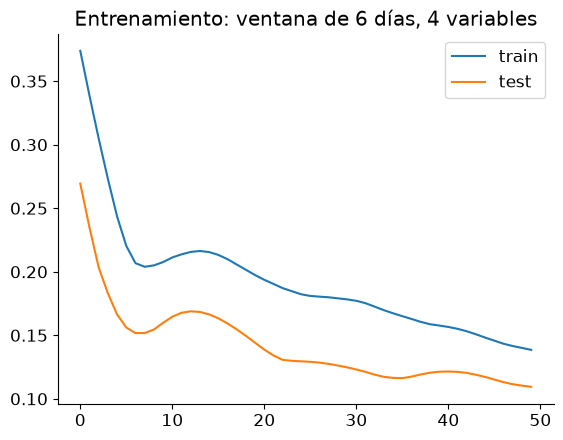

In [11]:
#Crea y entrena una LSTM para los datos preparados con preparar_datos.
def entrenar_modelo(datos, epochs=50, batch_size=72, verbose=2):
    n_days, n_vars = datos['train_X'].shape[1:]
    model = Sequential([
        Input(shape=(n_days, n_vars)),
        LSTM(50),
        Dense(1),
    ])
    model.compile(loss='mae', optimizer='adam')
    history = model.fit(
        datos['train_X'],
        datos['train_y'],
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(datos['test_X'], datos['test_y']),
        verbose=verbose,
        shuffle=False,
    )
    return model, history

model, history = entrenar_modelo(datos)

pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.title(f'Entrenamiento: ventana de {N_DAYS} días, {n_vars} variables')
pyplot.legend()
pyplot.show()

#### PASO 11. PREDICCIONES Y EVALUACIÓN DEL MODELO

La función **`evaluar(model, datos)`** predice sobre las últimas 4 semanas y devuelve las predicciones y los valores reales a la escala original mediante `scaler_y.inverse_transform`.

Después calcula la **raíz del error cuadrático medio (RMSE)**:

$$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ es la venta real, usada como objetivo de cobertura de demanda.
- $\hat{y}_i$ es la predicción de la red.
- $n$ es el número de muestras de prueba.

Un RMSE menor indica menos error **dentro de una misma categoría**. Su unidad corresponde a la cantidad vendida de esa familia.

Para interpretar el resultado también se calcula una referencia sencilla: **repetir la venta de hace siete días**. La evaluación es de un día por vez y utiliza las observaciones anteriores disponibles; no es una predicción de 28 días hecha desde una única fecha.

In [12]:
def evaluar(model, datos):
    yhat = model.predict(datos['test_X'], verbose=0)
    inv_yhat = datos['scaler_y'].inverse_transform(yhat)[:, 0]
    inv_y = datos['scaler_y'].inverse_transform(datos['test_y'].reshape(-1, 1))[:, 0]
    return sqrt(mean_squared_error(inv_y, inv_yhat))

rmse = evaluar(model, datos)
base_real = data_num[TARGET].iloc[N_TRAIN_DAYS:].to_numpy()
base_pred = data_num[TARGET].shift(7).iloc[N_TRAIN_DAYS:].to_numpy()
rmse_semanal = sqrt(mean_squared_error(base_real, base_pred))
print(f'Test RMSE LSTM ({CATEGORIA}): {rmse:.3f}')
print(f'Test RMSE repetir hace 7 días: {rmse_semanal:.3f}')

Test RMSE LSTM (BEVERAGES): 1913.161
Test RMSE repetir hace 7 días: 2336.960


#### PASO 12. FUNCIONES DE PREDICCIÓN

**1. `predecir(variables, ventana_dias, horizonte, fecha_fin, epochs, categoria)`**

Permite elegir las variables de entrada, cuántos días de historia utilizar y qué categoría se desea predecir. Si la configuración no se ha entrenado, utiliza las mismas funciones `preparar_datos` y `entrenar_modelo`; después guarda el modelo en el diccionario `modelos` para reutilizarlo.

| Parámetro | Uso |
|---|---|
| `variables` | Columnas de entrada, por ejemplo `['stock', 'promociones']` |
| `ventana_dias` | Días anteriores que recibe la red; por defecto, 6 |
| `horizonte` | 1 = día siguiente; 3 = tres días después del final de la ventana |
| `fecha_fin` | Último día de la ventana; si es `None`, toma la última fecha disponible |
| `epochs` | Épocas para una configuración nueva; por defecto, 50 |
| `categoria` | Familia de productos; por defecto, `BEVERAGES` |

La función selecciona la ventana, la normaliza, la aplana y la transforma a 3D. La LSTM calcula la salida y el escalador de Y la devuelve a la escala original. Si la fecha objetivo existe en el archivo, también se muestra el valor real.

**2. `predecir_categorias(categorias, ...)`**

Aplica `predecir` a varias familias y devuelve una tabla con **categoría, fecha y stock estimado**. Reutiliza los mismos cálculos, con un modelo y escaladores independientes por familia.

En los ejemplos siguientes se calcula primero una predicción individual y luego una tabla para bebidas, lácteos y frutas/verduras. `stock` representa cobertura estimada de demanda. Para convertirlo en una orden de compra haría falta conocer inventario disponible, reposiciones, plazos de entrega y stock de seguridad.

In [13]:
modelos = {(CATEGORIA, tuple(VARIABLES), N_DAYS, HORIZON): (model, datos)}

def predecir(variables=VARIABLES, ventana_dias=N_DAYS, horizonte=HORIZON,
             fecha_fin=None, epochs=50, categoria=CATEGORIA):
    """Predice stock necesario estimado a partir de ventas reales de una categoría."""
    if categoria not in DATOS_POR_CATEGORIA:
        raise ValueError(f'Categoría no válida: {categoria}')
    data_num = DATOS_POR_CATEGORIA[categoria]
    variables = list(variables)
    if not isinstance(ventana_dias, int) or not isinstance(horizonte, int) or ventana_dias < 1 or horizonte < 1:
        raise ValueError('La ventana y el horizonte deben ser enteros positivos.')
    fin = len(data_num) - 1 if fecha_fin is None else data_num.index.get_loc(pd.Timestamp(fecha_fin))
    inicio = fin - ventana_dias + 1
    if inicio < 0:
        raise ValueError('No hay suficientes días antes de fecha_fin.')
    clave = (categoria, tuple(variables), ventana_dias, horizonte)
    if clave not in modelos:
        print(f'Entrenando modelo para {categoria}, variables {variables}, ventana de {ventana_dias} días...')
        datos_cfg = preparar_datos(variables, ventana_dias, horizonte, categoria=categoria)
        modelo_cfg, _ = entrenar_modelo(datos_cfg, epochs=epochs, verbose=0)
        print(f'Test RMSE: {evaluar(modelo_cfg, datos_cfg):.3f}')
        modelos[clave] = (modelo_cfg, datos_cfg)
    modelo_cfg, datos_cfg = modelos[clave]
    ventana = data_num[variables].iloc[inicio:fin + 1]
    ventana_esc = datos_cfg['scaler_X'].transform(ventana.values)
    entrada = ventana_esc.reshape(1, -1)
    entrada_3d = entrada.reshape(1, ventana_dias, len(variables))
    pred_esc = modelo_cfg.predict(entrada_3d, verbose=0)
    pred = max(0.0, float(datos_cfg['scaler_y'].inverse_transform(pred_esc)[0, 0]))
    fecha_pred = data_num.index[fin] + pd.Timedelta(days=horizonte)
    print(f'Categoría: {categoria} | Variables: {variables}')
    print(f'Ventana: {ventana.index[0].date()} a {ventana.index[-1].date()} ({ventana_dias} días)')
    print(f'Entrada aplanada: {entrada.shape} | Entrada LSTM: {entrada_3d.shape}')
    print(f'Stock necesario estimado para {fecha_pred.date()}: {pred:.3f}')
    if fin + horizonte < len(data_num):
        print(f'Valor real: {data_num[TARGET].iloc[fin + horizonte]:.3f}')
        if fin + horizonte < N_TRAIN_DAYS:
            print('Esta fecha pertenece al entrenamiento, no mide rendimiento de prueba.')
    return pred


def predecir_categorias(categorias=CATEGORIAS, variables=VARIABLES,
                       ventana_dias=N_DAYS, horizonte=HORIZON, fecha_fin=None, epochs=50):
    """Aplica predecir a varias categorías y devuelve una tabla de cobertura estimada."""
    categorias = list(categorias)
    if not categorias or any(c not in DATOS_POR_CATEGORIA for c in categorias):
        raise ValueError('Elige al menos una categoría válida.')
    filas = []
    for categoria in categorias:
        pred = predecir(variables, ventana_dias, horizonte, fecha_fin, epochs, categoria)
        fin = DATOS_POR_CATEGORIA[categoria].index[-1] if fecha_fin is None else pd.Timestamp(fecha_fin)
        filas.append({'categoria': categoria, 'fecha': fin + pd.Timedelta(days=horizonte),
                      'stock_estimado': pred})
    return pd.DataFrame(filas)

In [14]:
# Predicción individual con el modelo ya entrenado y una fecha del periodo de prueba.
predecir(fecha_fin='2017-07-21')

Categoría: BEVERAGES | Variables: ['stock', 'promociones', 'dia_sin', 'dia_cos']
Ventana: 2017-07-16 a 2017-07-21 (6 días)
Entrada aplanada: (1, 24) | Entrada LSTM: (1, 6, 4)
Stock necesario estimado para 2017-07-22: 12674.136
Valor real: 15048.000
Out[0]: 12674.1357421875


Categoría: BEVERAGES | Variables: ['stock', 'promociones', 'dia_sin', 'dia_cos']
Ventana: 2017-08-08 a 2017-08-13 (6 días)
Entrada aplanada: (1, 24) | Entrada LSTM: (1, 6, 4)
Stock necesario estimado para 2017-08-14: 10602.223
Entrenando modelo para DAIRY, variables ['stock', 'promociones', 'dia_sin', 'dia_cos'], ventana de 6 días...
Test RMSE: 463.106
Categoría: DAIRY | Variables: ['stock', 'promociones', 'dia_sin', 'dia_cos']
Ventana: 2017-08-08 a 2017-08-13 (6 días)
Entrada aplanada: (1, 24) | Entrada LSTM: (1, 6, 4)
Stock necesario estimado para 2017-08-14: 2720.877
Entrenando modelo para PRODUCE, variables ['stock', 'promociones', 'dia_sin', 'dia_cos'], ventana de 6 días...
Test RMSE: 1955.927
Categoría: PRODUCE | Variables: ['stock', 'promociones', 'dia_sin', 'dia_cos']
Ventana: 2017-08-08 a 2017-08-13 (6 días)
Entrada aplanada: (1, 24) | Entrada LSTM: (1, 6, 4)
Stock necesario estimado para 2017-08-14: 9809.686
Out[0]: 
   categoria      fecha  stock_estimado
0  BEVERAGES 2017-0

,categoria,rmse_lstm,rmse_semanal
0,BEVERAGES,1913.160540,2336.960205
1,DAIRY,463.105600,319.766040
2,PRODUCE,1955.926954,1044.808535


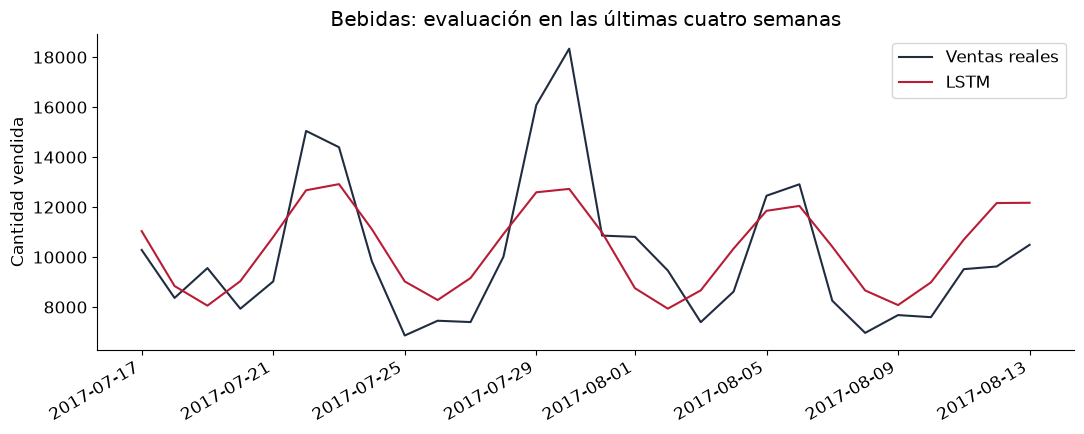

In [15]:
# Segunda función: tabla para bebidas, lácteos y frutas/verduras el 14/08/2017.
predicciones = predecir_categorias(['BEVERAGES', 'DAIRY', 'PRODUCE'])
resultados = []
for categoria in predicciones['categoria']:
    modelo_cat, datos_cat = modelos[(categoria, tuple(VARIABLES), N_DAYS, HORIZON)]
    serie = DATOS_POR_CATEGORIA[categoria][TARGET]
    baseline = sqrt(mean_squared_error(serie.iloc[N_TRAIN_DAYS:], serie.shift(7).iloc[N_TRAIN_DAYS:]))
    resultados.append({'categoria': categoria, 'rmse_lstm': evaluar(modelo_cat, datos_cat), 'rmse_semanal': baseline})

display(pd.DataFrame(resultados))

fig, ax = pyplot.subplots(figsize=(11, 4.5))
fechas_test = data_num.index[N_TRAIN_DAYS:]
reales = datos['scaler_y'].inverse_transform(datos['test_y'].reshape(-1, 1))[:, 0]
estimadas = datos['scaler_y'].inverse_transform(model.predict(datos['test_X'], verbose=0))[:, 0]
ax.plot(fechas_test, reales, label='Ventas reales', color='#202D40')
ax.plot(fechas_test, estimadas, label='LSTM', color='#B91C35')
ax.set(title='Bebidas: evaluación en las últimas cuatro semanas', ylabel='Cantidad vendida')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
pyplot.show()
predicciones

<div id="Conclusiones" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Conclusiones</h2> </div>

**Paso 13. Interpretar los resultados y reconocer sus límites**

En esta práctica se ha explorado una serie temporal real de un supermercado de Ecuador y se ha utilizado una red LSTM para estimar la demanda del día siguiente.

**Patrones observados en las 12 semanas:**

- El domingo presenta el mayor promedio diario en bebidas, lácteos, frutas/verduras, panadería y limpieza. En carnes, el máximo ocurre el viernes.
- Bebidas vende el domingo un **46,6% más** que su promedio diario. Carnes vende el viernes un **67,6% más** que su promedio diario.
- Al comparar las últimas cuatro semanas con las primeras cuatro, lácteos disminuye **12,4%** y bebidas **10,0%**. Limpieza aumenta **1,4%**.

**Interpretación del modelo:** la LSTM obtiene menos RMSE que la referencia semanal en bebidas. En lácteos y frutas/verduras, repetir la venta de hace siete días obtiene menos error. La red no mejora automáticamente una referencia sencilla, especialmente con solo ocho semanas de entrenamiento.

**Alcance:** los resultados describen una tienda y un periodo de 2017. No prueban que una promoción cause los cambios ni se generalizan automáticamente a todos los supermercados del país. Las ventas observadas también pueden estar limitadas por faltantes de inventario.

La salida `stock` es una estimación de la demanda que se desea cubrir. El dataset no contiene existencias reales de bodega. Las funciones permiten cambiar variables, ventana, horizonte y categoría para estudiar otras configuraciones.

<div id="Referencias" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Referencias</h2> </div>

[1] Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer.

[2] P. Joshi. (2017). *Artificial intelligence with python*. Packt Publishing Ltd.

**Datos reales utilizados:**

[3] [Kaggle: Store Sales – Time Series Forecasting, Corporación Favorita](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data).

[4] [Copia pública exacta descargada, fijada a una revisión del repositorio](https://raw.githubusercontent.com/kartikajls/Store-Sales-Time-Series-Forecasting/c6eac8b828c7c8231320dafbe0257f3466005fbe/store-sales-time-series-forecasting.zip).

Se seleccionaron las filas de `train.csv` con `store_nbr == 44` y fechas entre `2017-05-22` y `2017-08-13`, inclusive. Los metadatos de `stores.csv` sitúan la tienda 44 en Quito, Pichincha. El local está anonimizado y no se identifica su dirección ni su marca comercial concreta.

El archivo incluido `Datasets/ventas_12_semanas.csv` conserva las seis columnas y los valores de esas 2.772 filas. La descarga se realizó el 23 de octubre de 2026. No se fabricaron ventas ni datos de inventario.

**Huella SHA-256 del CSV incluido:**

```text
5f1734770419cf26102a481175bc1312689bb52740ba329d86b61a12231721b4
```

**Documentación de TensorFlow y Keras:**

[5] [Capa LSTM en Keras](https://keras.io/api/layers/recurrent_layers/lstm/).

[6] [Capa LSTM en TensorFlow](https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM).

Los siete CSV originales se conservan localmente en `Datasets/`, sin modificar sus bytes, y están excluidos de Git. El repositorio incluye el recorte necesario para ejecutar la práctica. `test.csv` y `sample_submission.csv` pertenecen a la competencia de Kaggle y no sustituyen las cuatro semanas de prueba con ventas conocidas que utiliza esta práctica.

**Huella SHA-256 del ZIP de origen verificado antes de copiar los archivos:**

```text
12e9c1dc4833cc804b3ff1515bd7b688f45fd8216fb2b340525036b006d625be
```